In [13]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from imblearn.under_sampling import RandomUnderSampler

PROJECT_ROOT = Path.cwd()
# If the notebook was opened from another working directory, locate the project root.
while not (PROJECT_ROOT / "data" / "raw" / "paysim.csv").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "paysim.csv"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Put paysim.csv in data/raw/ and rerun this cell."
    )

print("Project root:", PROJECT_ROOT)
print("Dataset:", DATA_PATH)


Project root: d:\DATA SCIENCE COURSE\ML\ML_Projects\Fraud-Detection-mlops
Dataset: d:\DATA SCIENCE COURSE\ML\ML_Projects\Fraud-Detection-mlops\data\raw\paysim.csv


In [14]:
# Full data load is required for the stratified split below.
# If your computer runs low on memory, tell me before running this cell.
df = pd.read_csv(DATA_PATH, low_memory=False)
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [15]:
# Basic quality checks
required_columns = [
    "step", "type", "amount", "nameOrig", "oldbalanceOrg",
    "newbalanceOrig", "nameDest", "oldbalanceDest",
    "newbalanceDest", "isFraud", "isFlaggedFraud"
]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("Missing values by column:")
display(df.isna().sum().to_frame("missing_count"))

print("Duplicate rows:", int(df.duplicated().sum()))
print("Fraud counts:")
display(df["isFraud"].value_counts().sort_index().to_frame("count"))
print("Fraud percentage:")
display((df["isFraud"].value_counts(normalize=True).sort_index() * 100).round(4).to_frame("percentage"))

if df["isFraud"].isna().any() or not df["isFraud"].isin([0, 1]).all():
    raise ValueError("isFraud must be non-missing and contain only 0/1.")
if df["amount"].isna().any() or (df["amount"] < 0).any():
    raise ValueError("amount must be non-missing and non-negative.")


Missing values by column:


,missing_count
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


Duplicate rows: 0
Fraud counts:


,count
isFraud,
0,6354407
1,8213


Fraud percentage:


,percentage
isFraud,
0,99.8709
1,0.1291


,transactions,fraud_cases,fraud_rate,fraud_rate_percent
type,,,,
TRANSFER,532909,4097,0.007688,0.768799
CASH_OUT,2237500,4116,0.001840,0.183955
CASH_IN,1399284,0,0.000000,0.000000
DEBIT,41432,0,0.000000,0.000000
PAYMENT,2151495,0,0.000000,0.000000


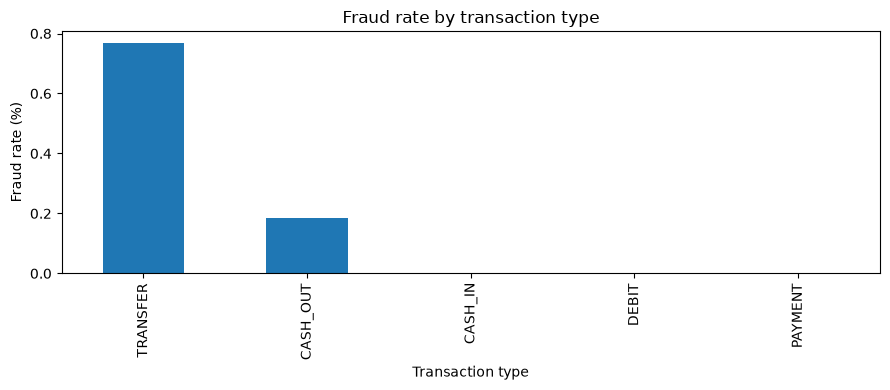

In [16]:
# Explore fraud rate by transaction type
type_summary = (
    df.groupby("type", observed=False)["isFraud"]
      .agg(transactions="size", fraud_cases="sum", fraud_rate="mean")
      .sort_values("fraud_rate", ascending=False)
)
type_summary["fraud_rate_percent"] = type_summary["fraud_rate"] * 100
display(type_summary)

ax = type_summary["fraud_rate_percent"].plot(kind="bar", figsize=(9, 4), title="Fraud rate by transaction type")
ax.set_xlabel("Transaction type")
ax.set_ylabel("Fraud rate (%)")
plt.tight_layout()
plt.show()


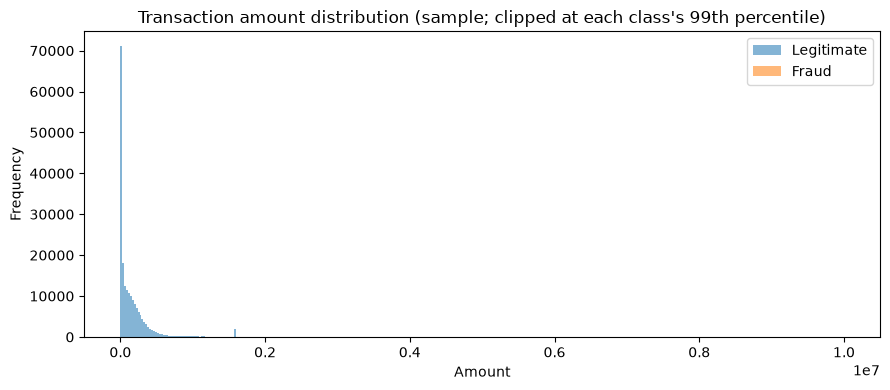

In [17]:
# Compare transaction amounts without allowing a few extreme values to dominate the plot
plot_sample = df.sample(n=min(200_000, len(df)), random_state=42)
fig, ax = plt.subplots(figsize=(9, 4))
for label, group in plot_sample.groupby("isFraud"):
    ax.hist(group["amount"].clip(upper=group["amount"].quantile(0.99)), bins=60,
            alpha=0.55, label="Fraud" if label == 1 else "Legitimate")
ax.set_title("Transaction amount distribution (sample; clipped at each class's 99th percentile)")
ax.set_xlabel("Amount")
ax.set_ylabel("Frequency")
ax.legend()
plt.tight_layout()
plt.show()


In [18]:
# Create modelling features and target.
# Keep the raw dataframe unchanged; model identifiers are removed because they are
# high-cardinality IDs, and isFlaggedFraud is excluded to avoid relying on a
# rule-generated indicator that may not be available consistently at prediction time.
target = "isFraud"
drop_columns = ["isFraud", "nameOrig", "nameDest", "isFlaggedFraud"]
X = df.drop(columns=drop_columns, errors="ignore").copy()
y = df[target].astype("int8").copy()

# 'type' is categorical and must be encoded later by the model pipeline.
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
print("Categorical features:", categorical_features)
print("Numeric features:", numeric_features)
print("X shape:", X.shape, "| y shape:", y.shape)


Categorical features: ['type']
Numeric features: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
X shape: (6362620, 7) | y shape: (6362620,)


C:\Users\vaish\AppData\Local\Temp\ipykernel_23520\1459484653.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()


In [19]:
# Stratified 70/15/15 split. Keep validation and test sets at the original class ratio.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

split_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "rows": [len(y_train), len(y_val), len(y_test)],
    "fraud_cases": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "fraud_percent": [float(y_train.mean()*100), float(y_val.mean()*100), float(y_test.mean()*100)]
})
display(split_summary)


,split,rows,fraud_cases,fraud_percent
0,train,4453834,5749,0.129080
1,validation,954393,1232,0.129087
2,test,954393,1232,0.129087


In [20]:
# Apply undersampling ONLY to training data. Never resample validation/test.
sampler = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = sampler.fit_resample(X_train, y_train)

print("Original training label counts:")
display(y_train.value_counts().sort_index().to_frame("count"))
print("Undersampled training label counts:")
display(y_train_under.value_counts().sort_index().to_frame("count"))
print("Validation label counts (unchanged):")
display(y_val.value_counts().sort_index().to_frame("count"))
print("Test label counts (unchanged):")
display(y_test.value_counts().sort_index().to_frame("count"))


Original training label counts:


,count
isFraud,
0,4448085
1,5749


Undersampled training label counts:


,count
isFraud,
0,5749
1,5749


Validation label counts (unchanged):


,count
isFraud,
0,953161
1,1232


Test label counts (unchanged):


,count
isFraud,
0,953161
1,1232


In [21]:
# Save as Parquet if a Parquet engine is installed; otherwise save CSV.
# CSV is slower/larger, but pandas can write it without an additional engine.
def save_frame(frame, stem):
    parquet_path = PROCESSED_DIR / f"{stem}.parquet"
    try:
        frame.to_parquet(parquet_path, index=False)
        return str(parquet_path)
    except (ImportError, ModuleNotFoundError):
        csv_path = PROCESSED_DIR / f"{stem}.csv"
        frame.to_csv(csv_path, index=False)
        return str(csv_path)

# Save original-distribution splits, plus the undersampled training split.
paths = {}
paths["X_train_under"] = save_frame(X_train_under, "X_train_under")
paths["y_train_under"] = save_frame(y_train_under.to_frame(name=target), "y_train_under")
paths["X_val"] = save_frame(X_val, "X_val")
paths["y_val"] = save_frame(y_val.to_frame(name=target), "y_val")
paths["X_test"] = save_frame(X_test, "X_test")
paths["y_test"] = save_frame(y_test.to_frame(name=target), "y_test")

(ARTIFACTS_DIR / "preprocessing_outputs.json").write_text(
    json.dumps(paths, indent=2), encoding="utf-8"
)
print(json.dumps(paths, indent=2))


{
  "X_train_under": "d:\\DATA SCIENCE COURSE\\ML\\ML_Projects\\Fraud-Detection-mlops\\data\\processed\\X_train_under.parquet",
  "y_train_under": "d:\\DATA SCIENCE COURSE\\ML\\ML_Projects\\Fraud-Detection-mlops\\data\\processed\\y_train_under.parquet",
  "X_val": "d:\\DATA SCIENCE COURSE\\ML\\ML_Projects\\Fraud-Detection-mlops\\data\\processed\\X_val.parquet",
  "y_val": "d:\\DATA SCIENCE COURSE\\ML\\ML_Projects\\Fraud-Detection-mlops\\data\\processed\\y_val.parquet",
  "X_test": "d:\\DATA SCIENCE COURSE\\ML\\ML_Projects\\Fraud-Detection-mlops\\data\\processed\\X_test.parquet",
  "y_test": "d:\\DATA SCIENCE COURSE\\ML\\ML_Projects\\Fraud-Detection-mlops\\data\\processed\\y_test.parquet"
}


In [22]:

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "data" / "processed").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Could not find data/processed")
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

def load_data(name):
    parquet_path = PROCESSED_DIR / f"{name}.parquet"
    csv_path = PROCESSED_DIR / f"{name}.csv"

    if parquet_path.exists():
        return pd.read_parquet(parquet_path)
    if csv_path.exists():
        return pd.read_csv(csv_path)

    raise FileNotFoundError(f"Missing dataset: {name}")

y_train = load_data("y_train_under")
y_val = load_data("y_val")
y_test = load_data("y_test")

for name, y in [
    ("Undersampled training data", y_train),
    ("Validation data", y_val),
    ("Test data", y_test),
]:
    print(f"\n{name}")
    print(y.value_counts().sort_index())
    print("\nClass percentages:")
    print((y.value_counts(normalize=True).sort_index() * 100).round(4))



Undersampled training data
isFraud
0          5749
1          5749
Name: count, dtype: int64

Class percentages:
isFraud
0          50.0
1          50.0
Name: proportion, dtype: float64

Validation data
isFraud
0          953161
1            1232
Name: count, dtype: int64

Class percentages:
isFraud
0          99.8709
1           0.1291
Name: proportion, dtype: float64

Test data
isFraud
0          953161
1            1232
Name: count, dtype: int64

Class percentages:
isFraud
0          99.8709
1           0.1291
Name: proportion, dtype: float64


In [23]:

print("Test data")
print(y_test.value_counts().sort_index())

print("\nTest class percentages")
print(
    (y_test.value_counts(normalize=True).sort_index() * 100)
    .round(4)
)


Test data
isFraud
0          953161
1            1232
Name: count, dtype: int64

Test class percentages
isFraud
0          99.8709
1           0.1291
Name: proportion, dtype: float64
